# Test evaluation across 100 seeds

Six model families, seeds **1–100**, and the parameters saved by the **25-trial inner searches**. Each final model is trained on the same 290 training events and evaluated on 80 fixed test events. No new tuning occurs. Every new fit must reproduce all saved validation predictions exactly before test evaluation.

Model choice remains fixed by mean validation Top@k%AUC: **CatBoost**, with the preselected **seed 42**. The test comparison is descriptive. Seed variation measures sensitivity to tuning and training randomness on these events; it is not uncertainty over new events.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research_snapshots.test_seed_sweep import DEFAULT_OUTPUT as OUTPUT
from research_snapshots.seed_sweep import MODELS
RUN_FITS = False  # Completed fits are verified and reused when enabled.
if RUN_FITS:
    subprocess.run([sys.executable, '-m', 'research_snapshots.test_seed_sweep', 'run', '--workers', 'all'], cwd=ROOT, check=True)
status = json.loads((OUTPUT / 'status.json').read_text())
display(status)
assert status['status'] == 'complete', 'Wait for all 600 fits before comparing the full distributions.'


{'status': 'complete',
 'completed_fits': 600,
 'expected_fits': 600,
 'validation_selected_model': 'catboost',
 'selected_seed': 42,
 'completed_by_model': {'catboost': 100,
  'catboost_es': 100,
  'forest': 100,
  'logistic': 100,
  'ranker': 100,
  'smote': 100},
 'selected_model_test_auc': 0.6954687500000001,
 'selected_model_validation_auc': 0.6285194174757281,
 'finished_at': '2026-11-12T13:22:05.592784+00:00'}

## Test Top@k%AUC distributions

The AUC is normalized over 0–20% using a 0.5 percentage-point grid. SD and quantiles summarize variation across 100 seed-specific fits. A win fraction counts seeds where a family ties for the highest test AUC; it does not select the portfolio model.

,count,mean,std,2.5%,50%,97.5%,win_fraction
model,,,,,,,
Logistic regression,100.0,0.703027,0.001504,0.698828,0.703281,0.704926,0.91
CatBoost,100.0,0.678603,0.021755,0.628281,0.685000,0.707086,0.06
CatBoost + ES,100.0,0.657650,0.039305,0.571969,0.666172,0.702516,0.03
Random forest,100.0,0.621183,0.020549,0.578430,0.623594,0.651453,0.00
CatBoost ranker,100.0,0.584550,0.029000,0.515734,0.589922,0.627969,0.00
CatBoost + SMOTE,100.0,0.508681,0.022755,0.453020,0.512109,0.542902,0.00


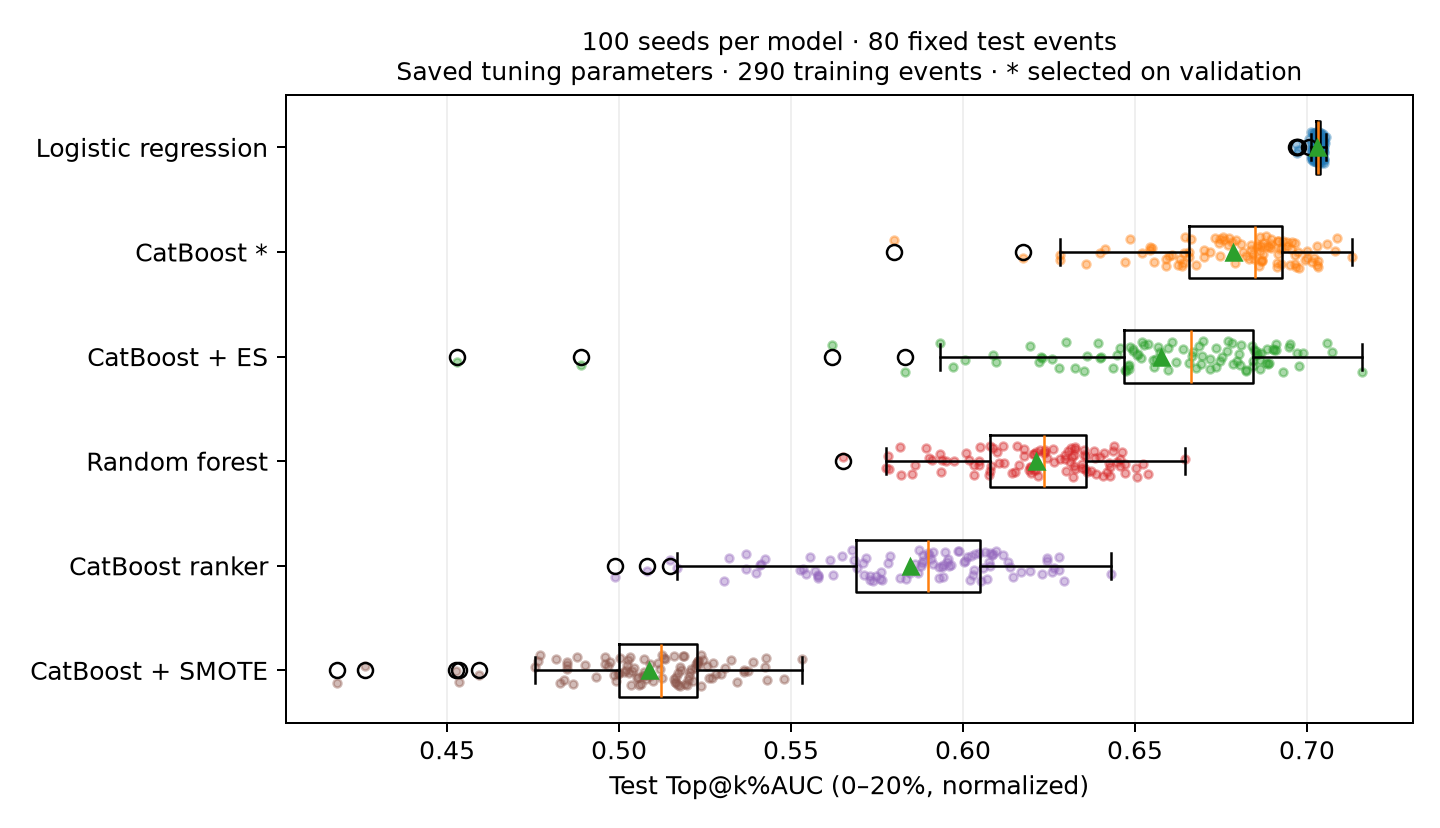

In [2]:
summary = pd.read_csv(OUTPUT / 'model_distributions.csv', index_col=0)
summary.index = summary.index.map(lambda key: MODELS[key][1])
display(summary[['count', 'mean', 'std', '2.5%', '50%', '97.5%', 'win_fraction']].round(6))
display(Image(filename=str(OUTPUT / 'test_seed_distributions.png')))


## Validation and test comparison

All seed-specific model parameters and training events are identical across these evaluations. Different event samples can produce different rankings.

In [3]:
comparison = pd.read_csv(OUTPUT / 'validation_test_comparison.csv', index_col=0)
comparison.index = comparison.index.map(lambda key: MODELS[key][1])
display(comparison.round(6))
results = pd.read_csv(OUTPUT / 'test_results.csv')
selected = results.loc[(results.model == status['validation_selected_model']) & (results.seed == status['selected_seed']), ['label', 'seed', 'validation_auc', 'test_auc', 'validation_predictions_identical']]
display(selected.reset_index(drop=True))


,validation_mean,validation_std,test_mean,test_std,test_minus_validation_mean
model,,,,,
CatBoost,0.615045,0.025148,0.678603,0.021755,0.063558
Logistic regression,0.610154,0.003640,0.703027,0.001504,0.092872
CatBoost + ES,0.590274,0.041845,0.657650,0.039305,0.067376
Random forest,0.563511,0.015440,0.621183,0.020549,0.057672
CatBoost ranker,0.518883,0.018295,0.584550,0.029000,0.065667
CatBoost + SMOTE,0.484913,0.018230,0.508681,0.022755,0.023769


,label,seed,validation_auc,test_auc,validation_predictions_identical
0,CatBoost,42,0.628519,0.695469,True


## Paired seed comparisons

These 95% intervals use 10,000 paired resamples of the 100 seed indices, holding the 80 test events fixed. They describe the mean difference across random seeds, not event-sampling uncertainty. The intervals are descriptive and are not multiplicity-adjusted tests.

In [4]:
pairs = pd.read_csv(OUTPUT / 'paired_seed_differences.csv')
view = pairs.drop(columns='scope').copy()
for column in ['model_a', 'model_b']:
    view[column] = view[column].map(lambda key: MODELS[key][1])
display(view.round(6))


,model_a,model_b,mean_difference,ci_lower,ci_upper
0,Logistic regression,Random forest,0.081844,0.077725,0.085977
1,Logistic regression,CatBoost,0.024423,0.020344,0.028814
2,Logistic regression,CatBoost + SMOTE,0.194345,0.190111,0.198922
3,Logistic regression,CatBoost ranker,0.118477,0.112831,0.124202
4,Logistic regression,CatBoost + ES,0.045377,0.038183,0.053541
5,Random forest,CatBoost,-0.057420,-0.063400,-0.051339
6,Random forest,CatBoost + SMOTE,0.112502,0.106451,0.119016
7,Random forest,CatBoost ranker,0.036633,0.029422,0.043924
8,Random forest,CatBoost + ES,-0.036467,-0.044845,-0.026964
9,CatBoost,CatBoost + SMOTE,0.169922,0.163834,0.176297


## Saved results and verification

Each `fits/<model>/seed_<seed>/` directory contains the final model, validation and test predictions, saved parameters and checksums. `test_event_metrics.parquet` contains the independently reconstructed event-level scores. Source searches and their validation-based selection remain unchanged.

Run `scripts/audit_test_seed_sweep.py` to reload both sets of checkpoints and verify every prediction, all 600 test scores and all 15 paired-seed intervals.

In [5]:
audit = json.loads((OUTPUT / 'audit.json').read_text())
display({key: audit[key] for key in ['status', 'completed_fits', 'training_events', 'validation_events', 'test_events', 'new_search_trials', 'validation_predictions_exactly_reproduced', 'test_predictions_reproduced_by_new_and_source_checkpoints', 'test_metrics_independently_replayed', 'paired_seed_comparisons_replayed', 'selected_model', 'selected_seed', 'elapsed_minutes']})
print('Saved artifacts:', OUTPUT)


{'status': 'PASS',
 'completed_fits': 600,
 'training_events': 290,
 'validation_events': 103,
 'test_events': 80,
 'new_search_trials': 0,
 'validation_predictions_exactly_reproduced': 600,
 'test_predictions_reproduced_by_new_and_source_checkpoints': 600,
 'test_metrics_independently_replayed': 600,
 'paired_seed_comparisons_replayed': 15,
 'selected_model': 'catboost',
 'selected_seed': 42,
 'elapsed_minutes': 32.609938783333334}

Saved artifacts: /home/borokoko/dev/pumps_and_dumps/notebooks/analysis_outputs/test_seed_sweep_100x25
